# Home Credit Default Risk: Exploratory Data Analysis

Author: Tiago Garcia Guimarães

## 1. Project Overview

Business question: which applicant characteristics are associated with loan default?

Dataset: Home Credit Default Risk (Kaggle), file application_train.csv, 307,511 loans and 122 columns.

Target variable: TARGET (1 = client had payment difficulties, 0 = all other cases).

Tools: Python (pandas, NumPy) in Jupyter.

In [1]:
# Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load data
df = pd.read_csv('../data/application_train.csv')

## 2. Data Loading and First Look

Before any analysis, I check the size of the dataset, the first rows, and the data type of each column.

In [2]:
df.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [3]:
df.shape

(307511, 122)

In [4]:
df.dtypes

SK_ID_CURR                      int64
TARGET                          int64
NAME_CONTRACT_TYPE             object
CODE_GENDER                    object
FLAG_OWN_CAR                   object
                               ...   
AMT_REQ_CREDIT_BUREAU_DAY     float64
AMT_REQ_CREDIT_BUREAU_WEEK    float64
AMT_REQ_CREDIT_BUREAU_MON     float64
AMT_REQ_CREDIT_BUREAU_QRT     float64
AMT_REQ_CREDIT_BUREAU_YEAR    float64
Length: 122, dtype: object

## 3. Target Variable

The target variable shows whether a client had payment difficulties. I check how balanced the two classes are.

In [5]:
df['TARGET'].value_counts(normalize=True)

TARGET
0    0.919271
1    0.080729
Name: proportion, dtype: float64

In [6]:
df['TARGET'].mean()

np.float64(0.08072881945686496)

## 4. Data Quality

I check missing values and unusual values before analyzing anything else.

In [7]:
df.isnull().sum().sort_values(ascending=False).head(10)

COMMONAREA_MEDI             214865
COMMONAREA_AVG              214865
COMMONAREA_MODE             214865
NONLIVINGAPARTMENTS_MODE    213514
NONLIVINGAPARTMENTS_AVG     213514
NONLIVINGAPARTMENTS_MEDI    213514
FONDKAPREMONT_MODE          210295
LIVINGAPARTMENTS_MODE       210199
LIVINGAPARTMENTS_AVG        210199
LIVINGAPARTMENTS_MEDI       210199
dtype: int64

In [8]:
df['DAYS_EMPLOYED'].describe()

count    307511.000000
mean      63815.045904
std      141275.766519
min      -17912.000000
25%       -2760.000000
50%       -1213.000000
75%        -289.000000
max      365243.000000
Name: DAYS_EMPLOYED, dtype: float64

In [9]:
df['DAYS_EMPLOYED'].describe()

count    307511.000000
mean      63815.045904
std      141275.766519
min      -17912.000000
25%       -2760.000000
50%       -1213.000000
75%        -289.000000
max      365243.000000
Name: DAYS_EMPLOYED, dtype: float64

In [10]:
(df['DAYS_EMPLOYED'] == 365243).sum()

np.int64(55374)

In [11]:
df['DAYS_EMPLOYED'] = df['DAYS_EMPLOYED'].replace (365243,np.nan)

In [12]:
df['DAYS_EMPLOYED'].isnull().sum()

np.int64(55374)

In [13]:
df[df['DAYS_EMPLOYED'].isnull()]['NAME_INCOME_TYPE'].value_counts()

NAME_INCOME_TYPE
Pensioner     55352
Unemployed       22
Name: count, dtype: int64

In [14]:
df['DAYS_EMPLOYED_MISSING'] = df['DAYS_EMPLOYED'].isnull()

In [15]:
df['DAYS_EMPLOYED_MISSING'].sum()

np.int64(55374)

## 5. Feature Engineering

I create new columns that make the data easier to read and analyze.

In [16]:
df['AGE_YEARS'] = -df['DAYS_BIRTH'] / 365

In [17]:
df['AGE_YEARS'].describe()

count    307511.000000
mean         43.936973
std          11.956133
min          20.517808
25%          34.008219
50%          43.150685
75%          53.923288
max          69.120548
Name: AGE_YEARS, dtype: float64

In [18]:
df['AGE_GROUP'] = pd.cut(df['AGE_YEARS'], bins = [20,30,40,50,60,70])

## 6. Default Rate Analysis

I compare the default rate across groups of clients.

In [19]:
df.groupby('AGE_GROUP', observed=False)['TARGET'].mean()

AGE_GROUP
(20, 30]    0.114569
(30, 40]    0.095835
(40, 50]    0.076508
(50, 60]    0.061297
(60, 70]    0.049214
Name: TARGET, dtype: float64

In [20]:
df.groupby('NAME_INCOME_TYPE')['TARGET'].mean().sort_values(ascending=False)

NAME_INCOME_TYPE
Maternity leave         0.400000
Unemployed              0.363636
Working                 0.095885
Commercial associate    0.074843
State servant           0.057550
Pensioner               0.053864
Businessman             0.000000
Student                 0.000000
Name: TARGET, dtype: float64

In [21]:
df.groupby('NAME_EDUCATION_TYPE')['TARGET'].mean().sort_values(ascending=False)

NAME_EDUCATION_TYPE
Lower secondary                  0.109277
Secondary / secondary special    0.089399
Incomplete higher                0.084850
Higher education                 0.053551
Academic degree                  0.018293
Name: TARGET, dtype: float64

## 7. Visualization

A chart makes the age pattern easier to see.

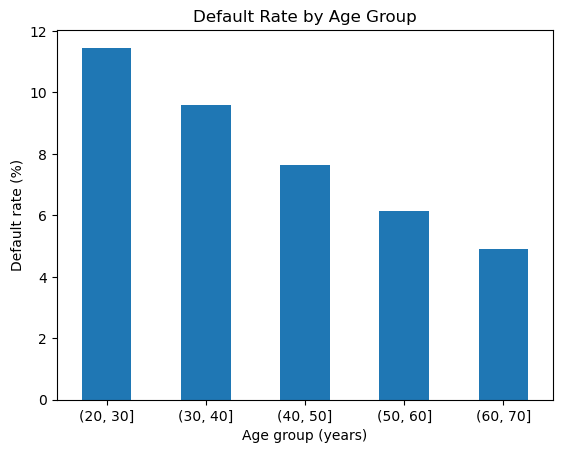

In [22]:
rate_by_age = df.groupby('AGE_GROUP', observed=False)['TARGET'].mean() * 100
rate_by_age.plot(kind='bar')
plt.title('Default Rate by Age Group')
plt.xlabel('Age group (years)')
plt.ylabel('Default rate (%)')
plt.xticks(rotation=0)
plt.show()

## 8. Save Cleaned Dataset

I save the cleaned dataset to use in the SQL and Tableau stages.

In [23]:
df.to_csv('../data/application_train_clean.csv', index=False)

## 9. Key Findings

1. The dataset is imbalanced: only 8.07% of clients had payment difficulties (TARGET = 1), so accuracy alone will be a misleading metric in the modeling stage.
2. DAYS_EMPLOYED has a placeholder value (365243) in 55,374 rows, almost all pensioners (55,352). I replaced it with NaN and created DAYS_EMPLOYED_MISSING to keep that information.
3. Default rate falls with age: 11.5% for clients aged 20 to 30 versus 4.9% for clients aged 60 to 70.
4. Default rate falls with education: 10.9% for Lower secondary versus 5.4% for Higher education. Academic degree shows 1.8%, but it has only 164 clients, so that rate is not reliable.
5. Maternity leave (40%) and Unemployed (36.4%) show the highest default rates, but these groups are very small (Unemployed has only 22 clients), so the rates are not reliable.

## 10. Next Steps

1. SQL: load the cleaned dataset into SQLite and answer business questions with queries.
2. Tableau: build a dashboard of default rate by age, education and income type.
3. Machine learning: train a classification model to predict default, handling the 92/8 class imbalance and evaluating with ROC AUC, precision and recall.